# PC5
Importar librerías y cargar datos

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestClassifier # Random Forest | dentro de módulo .ensemble
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier # Árbol de desición | dentro de módulo .tree

import utils_clasificacion as uc

## PARTE I
Reentrenar el Random Forest de Puerto Maldonado con los parámetros de la demo y aplicarlo a la zona de estudio asignada

In [122]:
AOI = ["puerto_maldonado","la_pampa"]
ANIO = 2025
CARPETA = "datos/"

# Agrupación de las clases de MapBiomas (nombre de la clase: códigos originales)
AGRUPACION = {
    "Bosque": [3],
    "Bosque inundable": [6],
    "Pasto, agropecuario y herbazal": [15, 21, 51],
    "Suelo sin vegetación": [23, 25],
    "Urbano": [24],
    "Minería": [30],
    "Agua": [33],
}

MUESTRAS_POR_CLASE = 1500
MIN_PIXELES = 2000
PROP_PRUEBA = 0.2
TAM_BLOQUE = 100
MODELO = "rf"
SEMILLA = 42
GUARDAR_FIGURAS = True

In [123]:
# Se cargan los datos de Puerto Maldonado para el entrenamiento del modelo
with rasterio.open(CARPETA + f"s2_bandas_{ANIO}_{AOI[0]}.tif") as src:
    pila_pue = src.read()
    bandas_pue = list(src.descriptions)
    extent_pue = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

with rasterio.open(CARPETA + f"mapbiomas_col4_{ANIO}_{AOI[0]}.tif") as src:
    mapbiomas_pue = src.read(1)

# Se cargan los datos de La Pampa para la predicción
with rasterio.open(CARPETA + f"s2_bandas_{ANIO}_{AOI[1]}.tif") as src:
    pila_pam= src.read()
    bandas_pam = list(src.descriptions)
    extent_pam = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

with rasterio.open(CARPETA + f"mapbiomas_col4_{ANIO}_{AOI[1]}.tif") as src:
    mapbiomas_pam = src.read(1)

print("Imagen, Puerto Maldonado:", pila_pue.shape, bandas_pue)
print("MapBiomas, Puerto Maldonado:", mapbiomas_pue.shape)
print("Imagen, La Pampa:", pila_pue.shape, bandas_pue)
print("MapBiomas, La Pampa:", mapbiomas_pue.shape)

Imagen, Puerto Maldonado: (6, 743, 744) ['B02', 'B03', 'B04', 'B08', 'B11', 'B12']
MapBiomas, Puerto Maldonado: (743, 744)
Imagen, La Pampa: (6, 743, 744) ['B02', 'B03', 'B04', 'B08', 'B11', 'B12']
MapBiomas, La Pampa: (743, 744)


In [124]:
# Puerto Maldonado 
grupos_pue, nombres_pue = uc.agrupar_clases(mapbiomas_pue, AGRUPACION)
n_bandas_pue, alto_pue, ancho_pue = pila_pue.shape

X_todo_pue = pila_pue.reshape(n_bandas_pue, -1).T
y_todo_pue = grupos_pue.ravel()
fil_pue, col_pue = np.divmod(np.arange(alto_pue * ancho_pue), ancho_pue)

val_pue = ~np.isnan(X_todo_pue).any(axis=1) & (y_todo_pue > 0)
X_todo_pue, y_todo_pue = X_todo_pue[val_pue], y_todo_pue[val_pue]
fil_pue, col_pue = fil_pue[val_pue], col_pue[val_pue]

print(f"Imagen: {alto_pue} x {ancho_pue} = {alto_pue * ancho_pue} píxeles")
print(f"Tabla:  {X_todo_pue.shape[0]} filas x {X_todo_pue.shape[1]} columnas")

ejemplo = np.random.default_rng(SEMILLA).choice(len(y_todo), size=6, replace=False)
tabla = pd.DataFrame(X_todo_pue[ejemplo], columns=bandas_pue).round(3)
tabla["clase"] = [nombres_pue[k - 1] for k in y_todo_pue[ejemplo]]
tabla

Imagen: 743 x 744 = 552792 píxeles
Tabla:  552218 filas x 6 columnas


,B02,B03,B04,B08,B11,B12,clase
0,0.026,0.050,0.033,0.338,0.218,0.107,"Pasto, agropecuario y herbazal"
1,0.023,0.044,0.026,0.289,0.150,0.062,Bosque
2,0.025,0.056,0.027,0.360,0.208,0.093,"Pasto, agropecuario y herbazal"
3,0.020,0.036,0.022,0.249,0.160,0.070,Bosque
4,0.023,0.044,0.025,0.284,0.154,0.068,Bosque inundable
5,0.018,0.035,0.021,0.245,0.121,0.052,Bosque inundable


In [125]:
idx_pue, clases_pue = uc.muestrear_por_clase(y_todo_pue, MUESTRAS_POR_CLASE, MIN_PIXELES, SEMILLA, nombres_pue)
X_pue, y_pue = X_todo_pue[idx_pue], y_todo_pue[idx_pue]
f_pue, c_pue = fil_pue[idx_pue], col_pue[idx_pue]
nombres_clases_pue = [nombres_pue[k - 1] for k in clases_pue]

pd.Series([nombres_pue[k - 1] for k in y_pue]).value_counts().rename("píxeles en la muestra").to_frame()

,píxeles en la muestra
Bosque inundable,1500
"Pasto, agropecuario y herbazal",1500
Bosque,1500
Minería,1500
Suelo sin vegetación,1500
Agua,1500
Urbano,1500


In [126]:
# Partición por bloques
es_prueba_bloques = uc.dividir_por_bloques(f_pue, c_pue, TAM_BLOQUE, PROP_PRUEBA, SEMILLA, y=y_pue)

In [127]:
X_ent_pue, X_pru_pue = X_pue[~es_prueba_bloques], X_pue[es_prueba_bloques]
y_ent_pue, y_pru_pue = y_pue[~es_prueba_bloques], y_pue[es_prueba_bloques]
print(f"Entrenamiento: {len(y_ent_pue)} píxeles   Prueba: {len(y_pru_pue)} píxeles")

bosque = RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1).fit(X_ent_pue, y_ent_pue)

Entrenamiento: 8480 píxeles   Prueba: 2020 píxeles


In [ ]:
# Datos de La Pampa para la predicción
grupos_pam, nombres_pam = uc.agrupar_clases(mapbiomas_pam, AGRUPACION)
colores = uc.colores_para(nombres_pam)

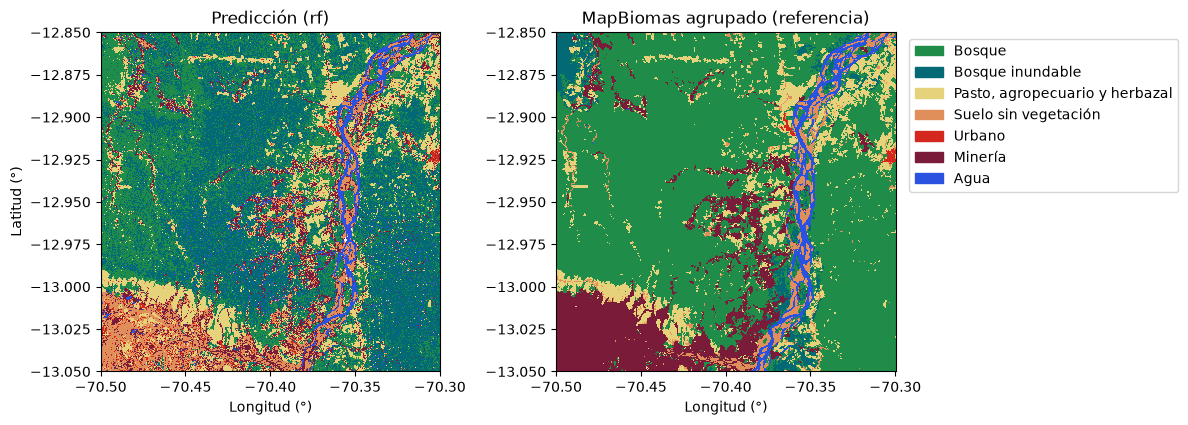

In [129]:
# PREDICCIÓN CON RF
mapa_pred = uc.predecir_imagen(bosque, pila_pam)

# Referencia con las mismas clases que el modelo (sin las clases descartadas)
referencia = np.where(np.isin(grupos_pam, clases_pue), grupos_pam, 0)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5.5))
opciones = dict(cmap=ListedColormap(colores), vmin=0.5, vmax=len(nombres_pam) + 0.5, extent=extent_pam, interpolation="nearest")
ejes[0].imshow(np.ma.masked_invalid(np.where(mapa_pred > 0, mapa_pred, np.nan)), **opciones)
ejes[0].set_title(f"Predicción ({MODELO})")
ejes[1].imshow(np.ma.masked_equal(referencia, 0), **opciones)
ejes[1].set_title("MapBiomas agrupado (referencia)")
uc.leyenda_clases(ejes[1], nombres_clases_pue, [colores[k - 1] for k in clases_pue], loc="upper left", bbox_to_anchor=(1.02, 1))
for ax in ejes:
    ax.set_xlabel("Longitud (°)")
ejes[0].set_ylabel("Latitud (°)")
plt.tight_layout()
plt.show()

Evaluar el desempeño por clase e indicar cuáles se predicen mejor, cuáles peor y cuáles no se identifican, explicando brevemente el criterio aplicado

In [112]:
n_bandas, alto_pam, ancho_pam = pila_pam.shape
X_todo_pam = pila_pam.reshape(n_bandas, -1).T
y_todo_pam = grupos_pam.ravel()
filas_pam, columnas_pam = np.divmod(np.arange(alto_pam * ancho_pam), ancho_pam)

val_pam = ~np.isnan(X_todo_pam).any(axis=1) & (y_todo_pam > 0)
X_todo_pam, y_todo_pam = X_todo_pam[val_pam], y_todo_pam[val_pam]
filas_pam, columnas_pam = filas_pam[val_pam], columnas_pam[val_pam]

Exactitud global en prueba: 0.435

                                Exactitud del usuario  \
Bosque                                          0.881   
Bosque inundable                                0.030   
Pasto, agropecuario y herbazal                  0.587   
Suelo sin vegetación                            0.252   
Urbano                                          0.088   
Minería                                         0.607   
Agua                                            0.554   

                                Exactitud del productor  Píxeles de prueba  
Bosque                                            0.389             361783  
Bosque inundable                                  0.308              19768  
Pasto, agropecuario y herbazal                    0.753              56050  
Suelo sin vegetación                              0.547              21012  
Urbano                                            0.629               1011  
Minería                                       

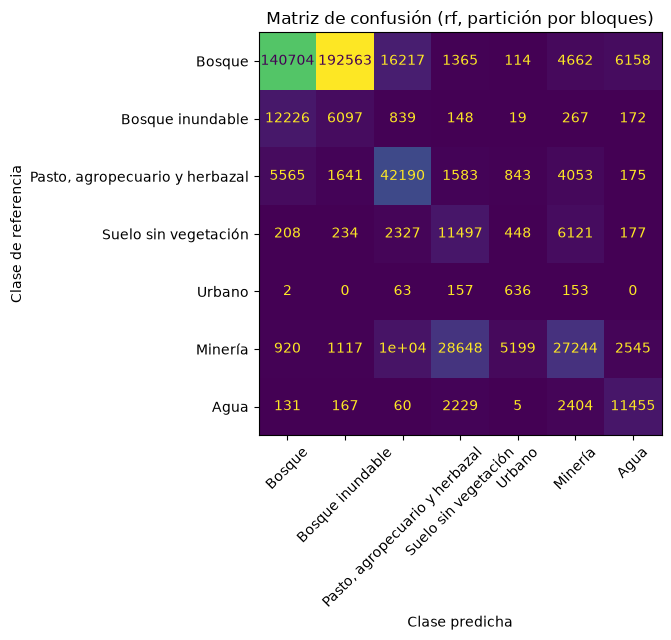

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
uc.evaluar(bosque, X_todo_pam, y_todo_pam, clases_pue, nombres_clases_pue, ax=ax,
           titulo=f"Matriz de confusión ({MODELO}, partición por bloques)")
plt.tight_layout()
plt.show()

Basándonos en el contraste entre la exactitud de productor y usuario presentadas por la matriz de confusión, se puede identificar que las clases mejor predichas son "Pasto, agropecuario y herbazal" y "Agua" ya que mantienen las exactitudes de productor más altas (75.3% y 69.6% respectivamente). Por otro lado, "Bosque inundable" y "Suelo sin vegetación" presentan un desempeño deficiente, mientras que la clase "Urbano" prácticamente no se identifica (8.8% de precisión) por su baja representación.

Argumentar a qué se pueden atribuir los resultados observados

Los resultados de la aplicación del modelo de "Puerto Maldonado" a "La Pampa" devuelven una exactitud global de 0.435. Ello indica que el modelo falló al ejecutarse sobre un espacio donde los valores de las bandas espectrales varían debido a las diferencias ambientales, geológicas y/o de cambio de uso de suelo propias de "La Pampa". Cabe destacar la alta confusión en la identificación entre "Bosque" y "Bosque inundable" con una exactitud del usuario de 0.03. Esto puede deberse a una posible estacionalidad de las imágenes, así como a la probable similitud entre valores de banda. De igual manera, la identificación de "Minería" y "Suelo sin vegetación" muestran una aceptable exactitud del usuario baja exactitud de productor (0.359) lo que resalta la complejidad de extrapolar modelos de predicción sin un reentrenamiento o calibración con muestras locales de la zona de interés.

## PARTE II
Entrenar un nuevo Random Forest con datos de la zona asignada. En lugar de conservar la profundidad por defecto, determinar la profundidad adecuada mediante un análisis previo que pueda sustentarse sin haber utilizado los datos con que se evaluará el modelo final

In [119]:
idx_pam, clases_pam = uc.muestrear_por_clase(y_todo_pam, MUESTRAS_POR_CLASE, MIN_PIXELES, SEMILLA, nombres_pam)
X_pam, y_pam = X_todo_pam[idx_pam], y_todo_pam[idx_pam]
f_pam, c_pam = filas_pam[idx_pam], columnas_pam[idx_pam]
nombres_clases_pam = [nombres_pam[k - 1] for k in clases_pam]

pd.Series([nombres_pam[k - 1] for k in y_pam]).value_counts().rename("píxeles en la muestra").to_frame()

Clase descartada por tener pocos píxeles (1011): Urbano


,píxeles en la muestra
Bosque inundable,1500
"Pasto, agropecuario y herbazal",1500
Suelo sin vegetación,1500
Bosque,1500
Agua,1500
Minería,1500


In [150]:
# Partición aleatoria
idx_ent_pam, idx_pru_pam = train_test_split(np.arange(len(y_pam)), test_size=PROP_PRUEBA, random_state=SEMILLA)
es_prueba_azar = np.zeros(len(y_pam), dtype=bool)
es_prueba_azar[idx_pru_pam] = True

# Partición por bloques
es_prueba_bloques = uc.dividir_por_bloques(f_pam, c_pam, TAM_BLOQUE, PROP_PRUEBA, SEMILLA, y=y_pam)

In [142]:
X_ent_pam, X_pru_pam = X_pam[~es_prueba_azar], X_pam[es_prueba_azar]
y_ent_pam, y_pru_pam = y_pam[~es_prueba_azar], y_pam[es_prueba_azar]

Entrenamiento: 7200 píxeles   Prueba: 1800 píxeles


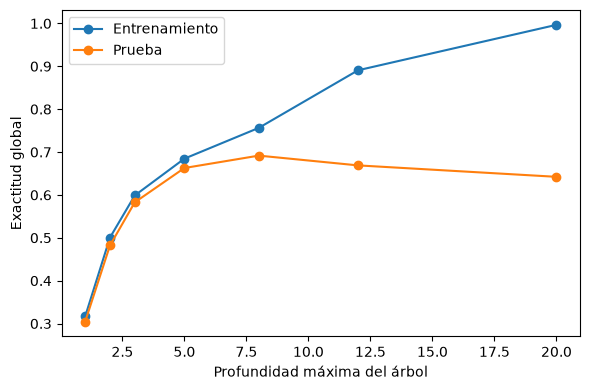

In [148]:
#  Efecto de la profundidad máxima en un árbol de decisión
profundidades = [1, 2, 3, 5, 8, 12, 20]
resultados = []
for d in profundidades:
    m = DecisionTreeClassifier(max_depth=d, random_state=SEMILLA).fit(X_ent_pam, y_ent_pam)
    resultados.append({"profundidad": d, "entrenamiento": m.score(X_ent_pam, y_ent_pam), "prueba": m.score(X_pru_pam, y_pru_pam)})
resultados = pd.DataFrame(resultados)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(resultados["profundidad"], resultados["entrenamiento"], marker="o", label="Entrenamiento")
ax.plot(resultados["profundidad"], resultados["prueba"], marker="o", label="Prueba")
ax.set_xlabel("Profundidad máxima del árbol")
ax.set_ylabel("Exactitud global")
ax.legend()
plt.tight_layout()
plt.show()

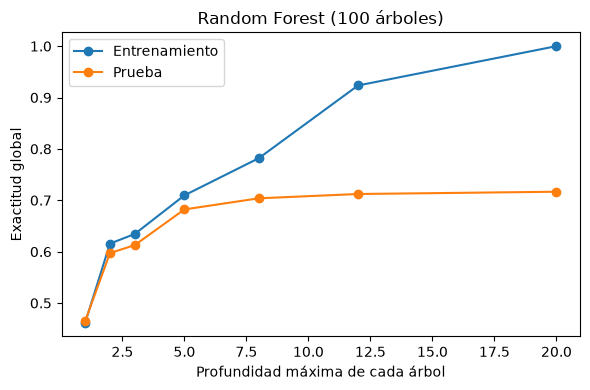

In [ ]:
# Efecto de la profundidad máxima de cada árbol en un Random Forest
resultados = []
for d in profundidades:
    m = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=SEMILLA, n_jobs=-1) # max_depth: número de niveles de decisión
    m.fit(X_ent_pam, y_ent_pam)
    resultados.append({"profundidad": d,
                       "entrenamiento": m.score(X_ent_pam, y_ent_pam),
                       "prueba": m.score(X_pru_pam, y_pru_pam)})
resultados = pd.DataFrame(resultados)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(resultados["profundidad"], resultados["entrenamiento"], marker="o", label="Entrenamiento")
ax.plot(resultados["profundidad"], resultados["prueba"], marker="o", label="Prueba")
ax.set_xlabel("Profundidad máxima de cada árbol")
ax.set_ylabel("Exactitud global")
ax.set_title("Random Forest (100 árboles)")
ax.legend()
plt.tight_layout()
plt.show()

In [149]:
arbol = DecisionTreeClassifier(max_depth=5,random_state=SEMILLA).fit(X_ent_pam, y_ent_pam)
bosque = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=SEMILLA, n_jobs=-1).fit(X_ent_pam, y_ent_pam)

for nombre, m in [("Árbol de decisión", arbol), ("Random Forest", bosque)]:
    print(f"{nombre:18s} entrenamiento {m.score(X_ent_pam, y_ent_pam):.3f}   prueba {m.score(X_pru_pam, y_pru_pam):.3f}")
print("Profundidad del árbol:", arbol.get_depth())

Árbol de decisión  entrenamiento 0.685   prueba 0.663
Random Forest      entrenamiento 0.710   prueba 0.682
Profundidad del árbol: 5


El tipo de partición de los datos (aleatoria o por bloques) queda a criterio de cada estudiante. Explicar los criterios que respaldan la elección final del modelo. Mostrar una figura que apoye el resultado

In [146]:
bosque_azar = RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1)
bosque_azar.fit(X_pam[~es_prueba_azar], y_pam[~es_prueba_azar])

print(f"Random Forest, exactitud en prueba con partición aleatoria:   {bosque_azar.score(X_pam[es_prueba_azar], y_pam[es_prueba_azar]):.3f}")
print(f"Random Forest, exactitud en prueba con partición por bloques: {bosque.score(X_pru_pam, y_pru_pam):.3f}")

Random Forest, exactitud en prueba con partición aleatoria:   0.711
Random Forest, exactitud en prueba con partición por bloques: 0.682


In [156]:
def correr_experimento(particion, semilla, tam_bloque=TAM_BLOQUE):
    """
    Entrena un Random Forest con una muestra por clase y devuelve la exactitud en prueba.

    Parámetros
    ----------
    particion (str) : "bloques" o "aleatoria", forma de separar entrenamiento y prueba.
    semilla (int) : Semilla para la generación de números aleatorios.
    tam_bloque (int) : Tamaño del bloque para la partición por bloques.

    Devuelve
    --------
    COMPLETAR
    """
    # 1. Muestra por clase
    idx, cls = uc.muestrear_por_clase(y_todo_pam, MUESTRAS_POR_CLASE, MIN_PIXELES, semilla)
    X, y = X_todo_pam[idx], y_todo_pam[idx]

    # 2. Partición. es_prueba vale True para los píxeles de prueba y False para los de entrenamiento
    if particion == "bloques":
        es_prueba = uc.dividir_por_bloques(filas_pam[idx], columnas_pam[idx], tam_bloque, PROP_PRUEBA, semilla, y=y)
    else:
        es_prueba = np.zeros(len(y), dtype=bool)
        ind_prueba = train_test_split(np.arange(len(y)), test_size=PROP_PRUEBA, random_state=semilla)[1]
        es_prueba[ind_prueba] = True

    # 3. Modelo entrenado solo con los datos de entrenamiento
    modelo = RandomForestClassifier(n_estimators=100, random_state=semilla, n_jobs=-1)
    modelo.fit(X[~es_prueba], y[~es_prueba])

    # 4. Exactitud en prueba
    return modelo.score(X[es_prueba], y[es_prueba])

In [ ]:
resultados = []
for particion in ("aleatoria", "bloques"):
    for semilla in range(42):
        exactitud = correr_experimento(particion, semilla)
        resultados.append({"particion": particion, "semilla": semilla, "exactitud": exactitud})

tabla = pd.DataFrame(resultados)
tabla.groupby("particion")["exactitud"].agg(["mean", "std"]).round(3)
# La tabla muestra una media mayor en la predicción de modelos por partición aleatoria, por lo que se usó este método para el entrenamiento del modelo final.

Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener pocos píxeles (1011): 5
Clase descartada por tener poco

,mean,std
particion,,
aleatoria,0.719,0.011
bloques,0.696,0.039


## PARTE III
Evaluar el modelo final de la parte 2 sobre los datos de prueba y presentar su matriz de confusión

Exactitud global en prueba: 0.682

                                Exactitud del usuario  \
Bosque                                          0.625   
Bosque inundable                                0.653   
Pasto, agropecuario y herbazal                  0.659   
Suelo sin vegetación                            0.780   
Minería                                         0.563   
Agua                                            0.899   

                                Exactitud del productor  Píxeles de prueba  
Bosque                                            0.603                312  
Bosque inundable                                  0.620                300  
Pasto, agropecuario y herbazal                    0.777                309  
Suelo sin vegetación                              0.533                306  
Minería                                           0.737                285  
Agua                                              0.837                288  


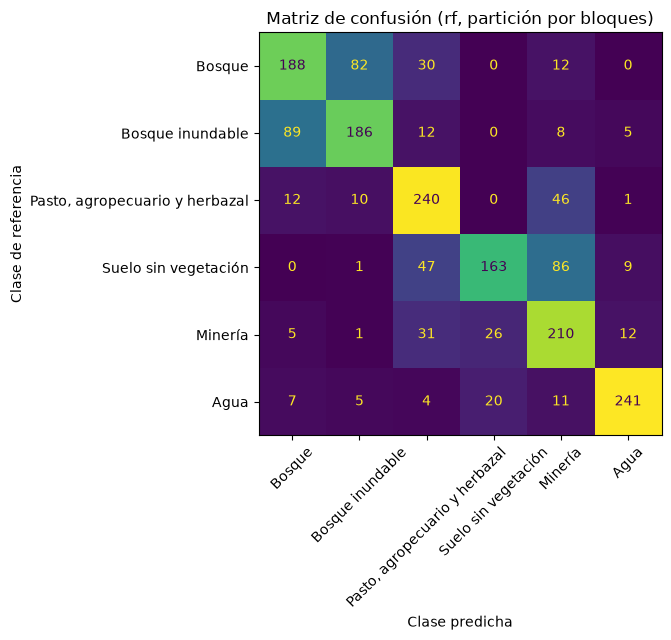

In [153]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
uc.evaluar(bosque, X_pru_pam, y_pru_pam, clases_pam, nombres_clases_pam, ax=ax,
           titulo=f"Matriz de confusión ({MODELO}, partición por bloques)")
plt.tight_layout()
plt.show()

Seleccionar una clase e interpretar su exactitud del usuario y del productor, y contrastarla con el desempeño de esa misma clase en la parte 1

Para esta sección, se realizará el contraste con la clase "Bosque inundable". Esta clase se predijo de forma poco precisa en el primer modelo (3% de exactitud de usuario); sin embargo, con el modelo de la parte 2 se registró una exactitud del usuario del 65.3% y una exactitud del productor del 62.0%. Esto es, que la mayor parte de los píxeles que el modelo predice como bosque inundable corresponden a dicha cobertura.
Entonces, el modelo y predicción de "La Pampa" redujo de forma drástica el error del primer modelo. Por ello, se rescata la importancia de entrenar y predecir dentro de una misma zona de estudio, con el fin de evitar la interferencia geográfica y logrando una representación espacial más coherente.

Guardar como figuras la matriz de confusión y la predicción final

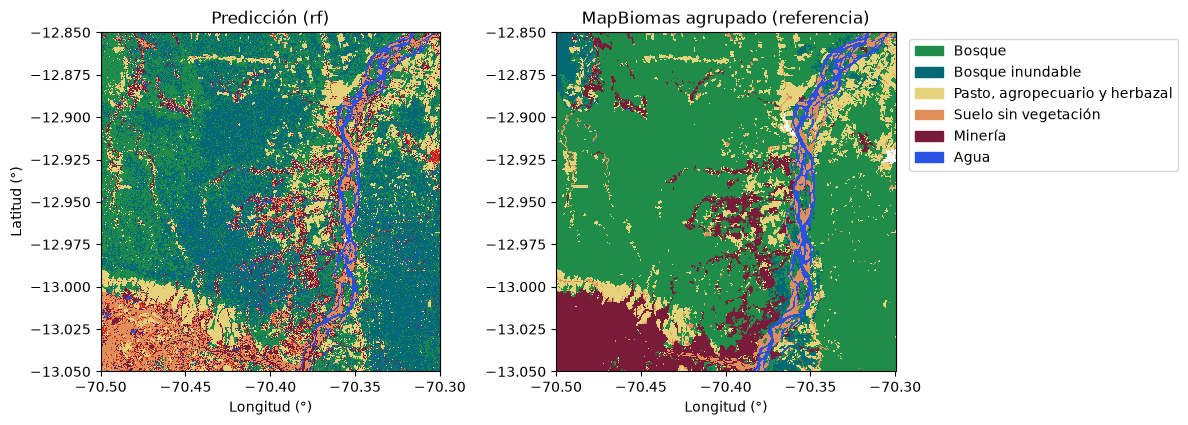

In [158]:
mapa_pred_pam = uc.predecir_imagen(bosque, pila_pam)

# Referencia con las mismas clases que el modelo (sin las clases descartadas)
referencia = np.where(np.isin(grupos_pam, clases_pam), grupos_pam, 0)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5.5))
opciones = dict(cmap=ListedColormap(colores), vmin=0.5, vmax=len(nombres_pam) + 0.5, extent=extent_pam, interpolation="nearest")
ejes[0].imshow(np.ma.masked_invalid(np.where(mapa_pred > 0, mapa_pred, np.nan)), **opciones)
ejes[0].set_title(f"Predicción ({MODELO})")
ejes[1].imshow(np.ma.masked_equal(referencia, 0), **opciones)
ejes[1].set_title("MapBiomas agrupado (referencia)")
uc.leyenda_clases(ejes[1], nombres_clases_pam, [colores[k - 1] for k in clases_pam], loc="upper left", bbox_to_anchor=(1.02, 1))
for ax in ejes:
    ax.set_xlabel("Longitud (°)")
ejes[0].set_ylabel("Latitud (°)")
plt.tight_layout()
plt.savefig('prediccionFinal.png',dpi=300, bbox_inches="tight")
plt.show()

Exactitud global en prueba: 0.670

                                Exactitud del usuario  \
Bosque                                          0.963   
Bosque inundable                                0.110   
Pasto, agropecuario y herbazal                  0.527   
Suelo sin vegetación                            0.552   
Minería                                         0.713   
Agua                                            0.737   

                                Exactitud del productor  Píxeles de prueba  
Bosque                                            0.648             361783  
Bosque inundable                                  0.612              19768  
Pasto, agropecuario y herbazal                    0.789              56050  
Suelo sin vegetación                              0.529              21012  
Minería                                           0.710              75840  
Agua                                              0.858              16451  


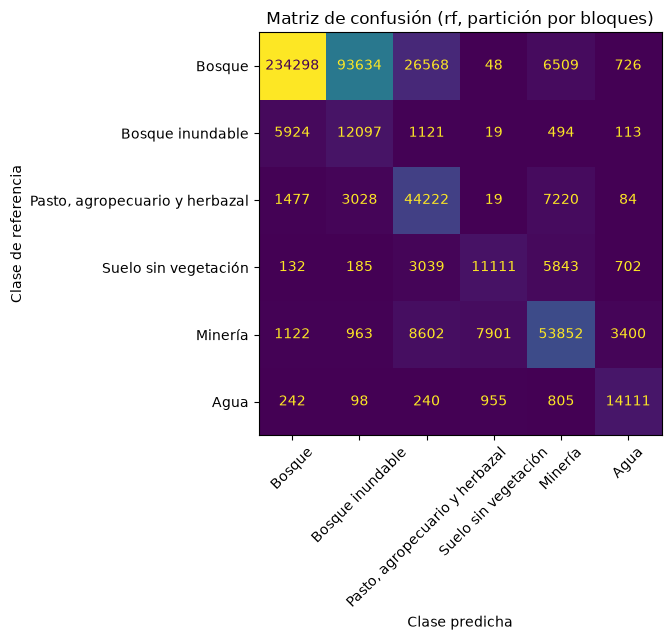

In [159]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
uc.evaluar(bosque, X_todo_pam, y_todo_pam, clases_pam, nombres_clases_pam, ax=ax,
           titulo=f"Matriz de confusión ({MODELO}, partición por bloques)")
plt.tight_layout()
plt.savefig('matrizDeConfusion.png',dpi=300, bbox_inches="tight")
plt.show()